# 01: Data cleaning and exploratory analysis

Week 1 of the mRNA-VIP project: profile `patient_records.csv`, handle missing values, and explore which features relate to adverse-reaction risk.

*Student engineering project on synthetic data. Not clinical guidance.*

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # run this notebook from the notebooks/ folder
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import data_pipeline as dp
import eda
from config import RAW_CSV

## 1. Load and profile

In [2]:
df_raw = dp.load_raw()          # also validates that all 7 required columns exist (FR-1.1)
stats = dp.profile(df_raw)
print("Shape:", stats["shape"])
print("\nMissing values per column:")
print(pd.Series(stats["missing"]).to_string())
print("\nClass balance (Reaction_Score):", stats["class_balance"])

Shape: (500, 7)

Missing values per column:
Patient_ID                  0
Age                         0
Biomarker_Level            20
Pre_Existing_Conditions     0
Vaccine_Dose_mcg            0
Prior_Reaction_History     17
Reaction_Score              0

Class balance (Reaction_Score): {0: 0.51, 1: 0.49}


In [3]:
df_raw.describe().round(2)

,Age,Biomarker_Level,Pre_Existing_Conditions,Vaccine_Dose_mcg,Reaction_Score
count,500.00,480.00,500.00,500.00,500.00
mean,51.44,5.28,1.26,86.55,0.49
std,19.44,2.84,1.20,36.23,0.50
min,18.00,0.64,0.00,25.10,0.00
25%,35.00,3.18,0.00,56.78,0.00
50%,51.00,4.82,1.00,84.55,0.00
75%,68.25,6.95,2.00,118.68,1.00
max,85.00,15.76,4.00,150.00,1.00


## 2. A data trap: the text "None"

`Prior_Reaction_History` uses the word `None` to mean *no prior reaction*. By default pandas treats that word as a missing value, which would make 291 genuine answers look blank. Compare the two ways of reading the file:

In [4]:
default_read = pd.read_csv(RAW_CSV)
print("Missing Prior_Reaction_History with pandas defaults:", default_read["Prior_Reaction_History"].isnull().sum())
print("Missing Prior_Reaction_History with our loader:     ", df_raw["Prior_Reaction_History"].isnull().sum())
df_raw["Prior_Reaction_History"].value_counts(dropna=False)

Missing Prior_Reaction_History with pandas defaults: 308
Missing Prior_Reaction_History with our loader:      17


Prior_Reaction_History
None        291
Mild        150
Moderate     42
NaN          17
Name: count, dtype: int64

## 3. Clean (FR-1.2)

Imputation instead of dropping rows: 37 of 500 rows have a gap, and dropping them would lose 7% of the data. The biomarker is right-skewed, so the **median** is used; the categorical column uses the **mode**.

In [5]:
df, log = dp.clean(df_raw)
for col in ("Biomarker_Level", "Prior_Reaction_History"):
    print(f"{col}: filled {log[col]['filled']} values with the {log[col]['strategy']} = {log[col]['value']}")
print("\nMissing values after cleaning:", int(df.isnull().sum().sum()))

Biomarker_Level: filled 20 values with the median = 4.82
Prior_Reaction_History: filled 17 values with the mode = None

Missing values after cleaning: 0


## 4. Distributions by risk class

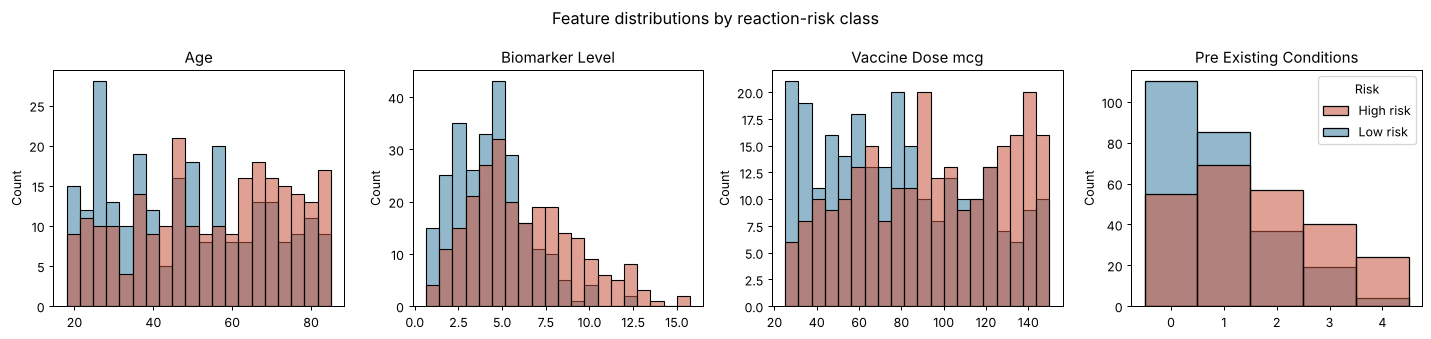

In [6]:
eda.plot_distributions(df, close=False);

Higher biomarker levels, more pre-existing conditions and larger doses all shift toward the High-risk class. Age has a weaker, gradual effect.

## 5. Correlations

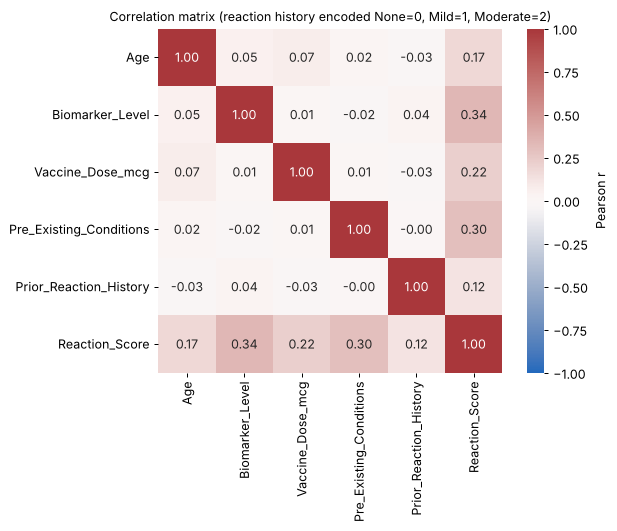

In [7]:
eda.plot_correlation(df, close=False);

In [8]:
encoded = df.assign(Prior_Reaction_History=df["Prior_Reaction_History"].map({"None": 0, "Mild": 1, "Moderate": 2}))
encoded.drop(columns="Patient_ID").corr()["Reaction_Score"].drop("Reaction_Score").sort_values(ascending=False).round(3)

Biomarker_Level            0.340
Pre_Existing_Conditions    0.301
Vaccine_Dose_mcg           0.224
Age                        0.174
Prior_Reaction_History     0.120
Name: Reaction_Score, dtype: float64

Every feature correlates positively with risk, but none strongly (all below 0.4), so the data is noisy and no single rule separates the classes. The features are almost uncorrelated with each other, so there is no multicollinearity problem for logistic regression.

## 6. Class balance and prior reactions

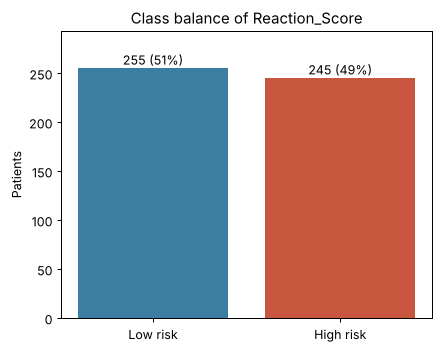

In [9]:
eda.plot_class_balance(df, close=False);

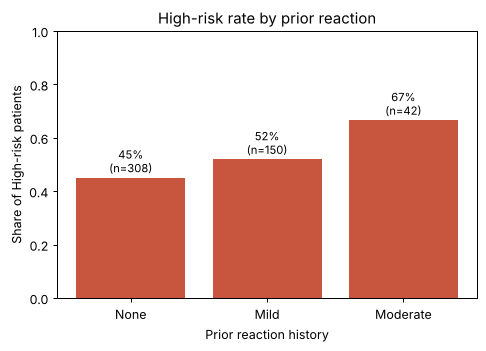

In [10]:
eda.plot_reaction_history(df, close=False);

The target is close to balanced (51% / 49%), so accuracy is a fair headline metric and no resampling is needed; F1 for the High-risk class is still used for model selection. The High-risk rate rises from None to Mild to Moderate, which supports encoding reaction history as an **ordered** number (None=0 < Mild=1 < Moderate=2) instead of the alphabetical order `LabelEncoder` would give.

**Next:** `python main.py train` trains and compares the two classifiers (results in `outputs/metrics/`).